<a href="https://colab.research.google.com/github/SidhPatel-27/dsa405-project/blob/main/DSA405_002_FA26_P4_smpate27.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import pandas as pd
import requests
import io
import time

# Create raw data folder if it doesn't already exist
os.makedirs('data/raw', exist_ok=True) #If it already exists leave it alone and move on
CACHE_FILE = "data/raw/wiki_climate.csv"
CACHE_FILE_WC = "data/raw/world_cup_standings.csv"

# If file is already caught, read that; Don't scrape again
if os.path.exists(CACHE_FILE):
    print(f"Found local file; Loading raw data directly from {CACHE_FILE}")
    df_climate = pd.read_csv(CACHE_FILE)
# If file is not found, scrape it from Wiki and save
else:
    print("No local file found; Scraping from Wikipedia")
    url_temp = "https://en.wikipedia.org/wiki/List_of_countries_by_average_yearly_temperature"

    # Send custom User-Agent so Wiki knows who we are to get permission
    headers = {'User-Agent': 'NCSU Student Project - smpate27@ncsu.edu'}
    response = requests.get(url_temp, headers=headers, timeout=20)

    # read_html grabs all tables; Only need first one saved in df_climate
    temp_tables = pd.read_html(io.StringIO(response.text)) #StringIO for new update, Had to look up on AI
    df_climate = temp_tables[0]

    # Save exact unmodified raw data to the raw folder
    df_climate.to_csv(CACHE_FILE, index=False)
    print(f"Scrape complete; Raw data saved to {CACHE_FILE}")


if os.path.exists(CACHE_FILE_WC):
    print(f"Found local file; Loading raw data directly from {CACHE_FILE_WC}")
    df_wc_raw = pd.read_csv(CACHE_FILE_WC)
else:
    print("No local file found; Beginning multi-page scrape...")
    headers = {'User-Agent': 'NCSU Student Project - smpate27@ncsu.edu'}

    tournament_years = [2014, 2018, 2022, 2026]
    all_standings = []
    for year in tournament_years:
        url = f"https://en.wikipedia.org/wiki/{year}_FIFA_World_Cup"
        print(f"Scraping {year} tournament: {url}")
        response = requests.get(url, headers=headers, timeout=20)

        if response.status_code != 200:
            raise ConnectionError(f"HTTP {response.status_code} on {url}")

        try:
            tables = pd.read_html(io.StringIO(response.text), match="Pos")
            df_year = None
            for tbl in tables:
                if len(tbl) >= 32 and "Pts" in tbl.columns and "Team" in tbl.columns:
                    df_year = tbl.copy()
                    break
            if df_year is None:
                raise ValueError(f"Could not find a 32+ row standings table for {year}")
            df_year['Tournament_Year'] = year
            all_standings.append(df_year)
        except ValueError:
            raise ValueError(f"Could not find the standings table for {year}")
        print("Sleeping for 2 seconds to respect Wikipedia's rate limit...")
        time.sleep(2)

    df_wc_raw = pd.concat(all_standings, ignore_index=True)
    df_wc_raw.to_csv(CACHE_FILE_WC, index=False)
    print(f"\nScrape complete! Raw data saved to {CACHE_FILE_WC}")


# Display the first few rows to verify
display(df_climate.head())
display(df_wc_raw.head())

Found local file; Loading raw data directly from data/raw/wiki_climate.csv
Found local file; Loading raw data directly from data/raw/world_cup_standings.csv


,Unnamed: 0,Country or region,Continent,Temperature
0,1,Burkina Faso,Africa,30.40 °C (86.72 °F)
1,2,Mali,Africa,29.21 °C (84.58 °F)
2,3,Aruba,South America,29.17 °C (84.51 °F)
3,4,Senegal,Africa,28.90 °C (84.02 °F)
4,5,Mauritania,Africa,28.82 °C (83.88 °F)


,Pos,Grp,Team,Pld,W,D,L,GF,GA,GD,Pts,Final result,Tournament_Year
0,1.0,G,Germany,7.0,6.0,1.0,0.0,18.0,4.0,+14,19.0,Champions,2014
1,2.0,F,Argentina,7.0,5.0,1.0,1.0,8.0,4.0,+4,16.0,Runners-up,2014
2,3.0,B,Netherlands,7.0,5.0,2.0,0.0,15.0,4.0,+11,17.0,Third place,2014
3,4.0,A,Brazil (H),7.0,3.0,2.0,2.0,11.0,14.0,−3,11.0,Fourth place,2014
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014


In [2]:
print("THE AUDIT\n")

# For each column in the dataframa, climate, print the name of said column
for col in df_climate.columns:
    print(f"\nCOLUMN: '{col}'")

    # Dtypes as they are loaded and as they should be
    loaded_dtype = df_climate[col].dtype
    expected_dtype = "float64" if "temperature" in col.lower() else "string/object"
    print(f"dtype as loaded: {loaded_dtype}")
    print(f"dtype as it should be: {expected_dtype}")

    # Missing values: count and rate
    missing = df_climate[col].isna().sum()
    rate = missing / len(df_climate)
    print(f"Missing values: {missing} (Rate: {rate:.1%})")

    # Distinct values for each column
    distinct = df_climate[col].nunique(dropna=False)
    print(f"Distinct values: {distinct}")

    # Min/Max/Range check for anything numeric
    if expected_dtype == "float64":
      temp_numeric = pd.to_numeric(df_climate[col], errors="coerce")
      valid_numeric = temp_numeric.dropna()
      if not valid_numeric.empty:
        min = valid_numeric.min()
        max = valid_numeric.max()
        print(f"Min value: {min}")
        print(f"Max value: {max}")
        print(f"Range: {max - min:.2f}")
      else:
        print("Min/Max/Range: Cannot compute, all Values loaded as text")

    # Full set of distinct values for anything categorical under 30 levels
    else:
      if distinct < 30:
        print(f"Factor levels: {df_climate[col].unique().tolist()}")
      else:
        print("Factor levels: Not printed(30 or more distinct values)")


THE AUDIT


COLUMN: 'Unnamed: 0'
dtype as loaded: int64
dtype as it should be: string/object
Missing values: 0 (Rate: 0.0%)
Distinct values: 235
Factor levels: Not printed(30 or more distinct values)

COLUMN: 'Country or region'
dtype as loaded: object
dtype as it should be: string/object
Missing values: 0 (Rate: 0.0%)
Distinct values: 235
Factor levels: Not printed(30 or more distinct values)

COLUMN: 'Continent'
dtype as loaded: object
dtype as it should be: string/object
Missing values: 0 (Rate: 0.0%)
Distinct values: 10
Factor levels: ['Africa', 'South America', 'Oceania', 'North America', 'Asia', 'Central America', 'Oceania and North America', 'Europe', 'Asia and Europe', 'Antarctica']

COLUMN: 'Temperature'
dtype as loaded: object
dtype as it should be: float64
Missing values: 0 (Rate: 0.0%)
Distinct values: 224
Min/Max/Range: Cannot compute, all Values loaded as text


Defects checked for but not found:


During this audit, multiple types of defects were explicitly checked for but not found. There were no obvious sentinel values(such as 999 or N/A). Inspection of the tail of the data confirmed there were no total or subtotal rows mixed in at the bottom of the table. A check of distinct values in the "Country or region" column showed there were no duplicate keys(every country is listed uniquely). Finally, the text was not garbled by wrong character encoding(the degree symbols ° formmatted correctly as seen in header). However the audit did reveal that numbers are stored as text in the Temperature column and a junk index column was imported, both of which will be addressed in the cleaning phase.

In [3]:
col_names = ["Variable name", "Type", "Units", "Factor levels", "Valid range", "Missingness", "Notes"]
rows = [
    [
        "country",
        "string",
        "N/A (Identifier)",
        "N/A (>30 levels)",
        "Valid recognized country names",
        "0 missing, would mean geography not properly recorded by Wikipedia",
        "Must standardize names (United States of America and USA) in P3 to match World Cup data."
    ],
    [
        "continent",
        "category",
        "N/A (Categorical)",
        "Africa, South America, Oceania, North America, Asia, Central America, Oceania and North America, Europe, Asia and Europe, Antarctica",
        "Earth's continents and major sub-regions",
        "0 missing, would mean geography not properly recorded by Wikipedia",
        "Contains some hybrid regions like 'Asia and Europe' for places like Russia."
    ],
    [
        "avg_temp_c",
        "float",
        "degrees in Celsius",
        "N/A (Numeric)",
        "-35.0 to 35.0",
        "0 missing, would mean the average temp for nation(s) wasnt properly recorded by Wikipedia",
        "Raw data had text like '30.40 °C (86.72 °F)'. Should represent a clean extracted celsius float."
    ],
    [
        "team",
        "string",
        "N/A (Identifier)",
        "N/A (>30 levels)",
        "The 48 qualifying 2026 World Cup teams",
        "0 missing, would mean that a team that qualfied, wasnt properly recorded by Wikipedia",
        "From Source 1 (Standings); Will be done in P3. To be used to merge with country from climate dataframe"
    ],
    [
        "pts_per_match",
        "float",
        "points",
        "N/A (Numeric)",
        "0.0 to 3.0",
        "0 missing, would mean that a team's average points, wasnt properly recorded by Wikipedia",
        "From Source 1 (Standings); Will be done in P3. Total points divided by matches played(3 for win, 1 for draw, 0 for loss)"
    ],
    [
        "gf_per_match",
        "float",
        "goals",
        "N/A (Numeric)",
        "N/A",
        "0 missing, would mean that a team's goals or matches, werent properly recorded by Wikipedia",
        "From Source 1 (Standings); Done in analysis; goals scored divided by matches played"
    ],
    [
        "ga_per_match",
        "float",
        "goals",
        "N/A (Numeric)",
        "N/A",
        "0 missing, would mean that a team's goals or matches, werent properly recorded by Wikipedia",
        "From Source 1 (Standings); Done in analysis; goals allowed divided by matches played"
    ],
    [
        "Pos",
        "float",
        "N/A (Identifier)",
        "N/A (>30 levels)",
        "1 to 48",
        "0 missing, would mean that a team's position in a tournament wasnt properly recorded by Wikipedia",
        "Where a team placed in the entire tournament"
    ],
    [
        "Grp",
        "String",
        "N/A (Categorical)",
        "A, B, C, D, E, F, G, H, I, J, K, L",
        "Letters A-L",
        "0 missing, would mean that a team's grouping in a tournament wasnt properly recorded by Wikipedia",
        "Where a team was placed during the group stage"
    ],
    [
        "Pld",
        "float",
        "matches played",
        "3, 4, 5, 6, 7, 8",
        "8 through 3",
        "0 missing, would mean that a team's played matches in a tournament wasnt properly recorded by Wikipedia",
        "Matches played in a tournament"
    ],
    [
        "W",
        "float",
        "matches won",
        "7, 6, 5, 4, 3, 2, 1, 0",
        "7 through 0",
        "0 missing, would mean that a team's won matches in a tournament wasnt properly recorded by Wikipedia",
        "Matches won in a tournament"
    ],
    [
        "D",
        "float",
        "matches drawn",
        "7, 6, 5, 4, 3, 2, 1, 0",
        "7 through 0",
        "0 missing, would mean that a team's tied matches in a tournament wasnt properly recorded by Wikipedia",
        "Matches tied in a tournament"
    ],
    [
        "L",
        "float",
        "matches lost",
        "7, 6, 5, 4, 3, 2, 1, 0",
        "7 through 0",
        "0 missing, would mean that a team's lost matches in a tournament wasnt properly recorded by Wikipedia",
        "Matches lost in a tournament"
    ],
    [
        "GF",
        "float",
        "goals for",
        "N/A (Numeric)",
        "0 or higher",
        "0 missing, would mean that a teams goal's made in a tournament wasnt properly recorded by Wikipedia",
        "Goals made in a tournament"
    ],
    [
        "GA",
        "float",
        "goals against",
        "N/A (Numeric)",
        "0 or higher",
        "0 missing, would mean that a teams goal's lost in a tournament wasnt properly recorded by Wikipedia",
        "Goals conceded in a tournament"
    ],
    [
        "GD",
        "string",
        "goal difference",
        "N/A (Numeric)",
        "N/A (Numeric)",
        "0 missing, would mean that a teams goal's difference in a tournament wasnt properly recorded by Wikipedia",
        "Goals made minus Goals conceded"
    ],
    [
        "Pts",
        "float",
        "points",
        "N/A (Numeric)",
        "0 or higher",
        "0 missing, would mean that a team's points in a tournament wasnt properly recorded by Wikipedia",
        "Total points by end of tournament(3 for win, 1 for draw, 0 for loss)"
    ],
    [
        "Final Result",
        "string",
        "N/A (Categorical)",
        "Champion, Runner-up, Third place, Fourth place, Eliminated in quarterfinals, Eliminated in round of 16, Eliminated in round of 32, Eliminated in group stage",
        "Valid result",
        "0 missing, would mean that a team's final result in a tournament wasnt properly recorded by Wikipedia",
        "Final position in the tournament by category"
    ],
    [
        "Tournament_Year",
        "float",
        "Year",
        "2014, 2018, 2022, 2026",
        "Years 2014-2026 with 4 year increments",
        "0 missing, would mean that a team's year in a tournament wasnt properly recorded by Wikipedia",
        "Year of the tournament the team qualified for"
    ],
    [
        "climate_join_key",
        "string",
        "N/A (Identifier)",
        "N/A (>30 levels)",
        "Valid recognized country names",
        "0 missing, would mean geography not properly recorded by Wikipedia",
        "Used for joining since the 2 sources had different names for the same country or had countries divded into multiple"
    ],
    [
        "native_climate_bucket",
        "string",
        "N/A (Categorical)",
        "1 - Coldest, 2 - Mild, 3 - Warm, 4 - Hottest",
        "1 of the 4 factors",
        "0 missing, would mean a nation was not sorted into a bucket",
        "Used for dividing the nations into categories of climates in comparison to each other"
    ],
    [
        "host_temp_c",
        "float",
        "degrees in Celsius",
        "N/A (Numeric)",
        "-35.0 to 35.0",
        "0 missing, would mean the average temp for a host nation wasnt properly recorded by Developer",
        "Manually input data from other source"
    ],
    [
        "climate_shock",
        "float",
        "degrees in Celsius",
        "N/A (Numeric)",
        "0 or higher",
        "0 missing, would mean that a temp difference for a nation wasnt properly recorded",
        "The absolute difference between avg_temp_c and host_temp_c"
    ],
    [
        "gd_per_match",
        "float",
        "goals",
        "N/A (Numeric)",
        "N/A",
        "0 missing, would mean that a team's goals difference in overall score, wasnt properly recorded by Wikipedia",
        "Done in analysis; goals scored minus goals conceded"
    ]

]

df_data_dict = pd.DataFrame(rows, columns=col_names)
display(df_data_dict)
# When running this code, convert df into an interactive table to view full contents


,Variable name,Type,Units,Factor levels,Valid range,Missingness,Notes
0,country,string,N/A (Identifier),N/A (>30 levels),Valid recognized country names,"0 missing, would mean geography not properly r...",Must standardize names (United States of Ameri...
1,continent,category,N/A (Categorical),"Africa, South America, Oceania, North America,...",Earth's continents and major sub-regions,"0 missing, would mean geography not properly r...",Contains some hybrid regions like 'Asia and Eu...
2,avg_temp_c,float,degrees in Celsius,N/A (Numeric),-35.0 to 35.0,"0 missing, would mean the average temp for nat...",Raw data had text like '30.40 °C (86.72 °F)'. ...
3,team,string,N/A (Identifier),N/A (>30 levels),The 48 qualifying 2026 World Cup teams,"0 missing, would mean that a team that qualfie...",From Source 1 (Standings); Will be done in P3....
4,pts_per_match,float,points,N/A (Numeric),0.0 to 3.0,"0 missing, would mean that a team's average po...",From Source 1 (Standings); Will be done in P3....
5,gf_per_match,float,goals,N/A (Numeric),N/A,"0 missing, would mean that a team's goals or m...",From Source 1 (Standings); Done in analysis; g...
6,ga_per_match,float,goals,N/A (Numeric),N/A,"0 missing, would mean that a team's goals or m...",From Source 1 (Standings); Done in analysis; g...
7,Pos,float,N/A (Identifier),N/A (>30 levels),1 to 48,"0 missing, would mean that a team's position i...",Where a team placed in the entire tournament
8,Grp,String,N/A (Categorical),"A, B, C, D, E, F, G, H, I, J, K, L",Letters A-L,"0 missing, would mean that a team's grouping i...",Where a team was placed during the group stage
9,Pld,float,matches played,"3, 4, 5, 6, 7, 8",8 through 3,"0 missing, would mean that a team's played mat...",Matches played in a tournament


In [4]:
df_clean = df_climate.copy()
df_clean = df_clean.drop(columns="Unnamed: 0")
df_clean = df_clean.rename(columns={"Country or region": "country","Continent": "continent","Temperature": "avg_temp_c"})
display(df_clean.head())

for v in sorted(df_clean.avg_temp_c.dropna().unique()):
    print(repr(v))

df_clean["avg_temp_c"] = df_clean["avg_temp_c"].str.replace('\xa0', ' ')
df_clean["avg_temp_c"] = df_clean["avg_temp_c"].str.split(' °C').str[0]

#Had to use AI to find out that I had to replace Unicode minus sign (−) with standard ASCII minus (-)
df_clean["avg_temp_c"] = df_clean["avg_temp_c"].str.replace('−', '-')

df_clean["avg_temp_c"] = df_clean["avg_temp_c"].astype(float)

for v in sorted(df_clean.avg_temp_c.dropna().unique()):
    print(repr(v))

df_clean["continent"] = df_clean["continent"].astype("category")
display(df_clean.head())
df_clean.info()

,country,continent,avg_temp_c
0,Burkina Faso,Africa,30.40 °C (86.72 °F)
1,Mali,Africa,29.21 °C (84.58 °F)
2,Aruba,South America,29.17 °C (84.51 °F)
3,Senegal,Africa,28.90 °C (84.02 °F)
4,Mauritania,Africa,28.82 °C (83.88 °F)


'1.07\xa0°C (33.93\xa0°F)'
'1.85\xa0°C (35.33\xa0°F)'
'10.02\xa0°C (50.04\xa0°F)'
'10.18\xa0°C (50.32\xa0°F)'
'10.35\xa0°C (50.63\xa0°F)'
'10.38\xa0°C (50.68\xa0°F)'
'10.46\xa0°C (50.83\xa0°F)'
'10.49\xa0°C (50.88\xa0°F)'
'10.67\xa0°C (51.21\xa0°F)'
'10.79\xa0°C (51.42\xa0°F)'
'10.89\xa0°C (51.60\xa0°F)'
'11.35\xa0°C (52.43\xa0°F)'
'11.40\xa0°C (52.52\xa0°F)'
'11.50\xa0°C (52.70\xa0°F)'
'11.66\xa0°C (52.99\xa0°F)'
'11.81\xa0°C (53.26\xa0°F)'
'11.96\xa0°C (53.53\xa0°F)'
'12.09\xa0°C (53.76\xa0°F)'
'12.22\xa0°C (54.00\xa0°F)'
'12.27\xa0°C (54.09\xa0°F)'
'12.38\xa0°C (54.28\xa0°F)'
'12.44\xa0°C (54.39\xa0°F)'
'12.83\xa0°C (55.09\xa0°F)'
'12.96\xa0°C (55.33\xa0°F)'
'13.02\xa0°C (55.44\xa0°F)'
'13.04\xa0°C (55.47\xa0°F)'
'13.05\xa0°C (55.49\xa0°F)'
'13.06\xa0°C (55.51\xa0°F)'
'13.07\xa0°C (55.53\xa0°F)'
'13.17\xa0°C (55.71\xa0°F)'
'14.50\xa0°C (58.10\xa0°F)'
'15.20\xa0°C (59.36\xa0°F)'
'15.45\xa0°C (59.81\xa0°F)'
'15.85\xa0°C (60.53\xa0°F)'
'16.30\xa0°C (61.34\xa0°F)'
'16.66\xa0°C (61.99\xa

,country,continent,avg_temp_c
0,Burkina Faso,Africa,30.40
1,Mali,Africa,29.21
2,Aruba,South America,29.17
3,Senegal,Africa,28.90
4,Mauritania,Africa,28.82


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235 entries, 0 to 234
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   country     235 non-null    object  
 1   continent   235 non-null    category
 2   avg_temp_c  235 non-null    float64 
dtypes: category(1), float64(1), object(1)
memory usage: 4.4+ KB


**REVISION 1  
What I Could Have Done Differently:**

I could have kept the Fahrenheit value as a second column, which would have allowed me to increase readability and understanding for viewers more used to the measurement. I chose not to due to the measurement feeling like a waste of space considering that the Celcius values can simply be converted by a mathmatical formula, if the need ever came up and that the vast majoirty of countries use Celcius as do proffessionals looking into statistics and sciences.

1. Column: Unnamed: 0  
Change made: Dropped the entire column.  
Rows/cells affected: 235 cells.  
Why: It was a useless integer index; it serves no purpose for analysis.  
What is lost: Nothing; it was just a row counter.  
2. Column: Country or region  
Change made: Renamed to country.  
Rows/cells affected: 235 cells (header).  
Why: Standardizes the variable name to lowercase, making it easier to code with and matching the data dictionary.  
What is lost: Nothing.  
3. Column: Continent  
Change made: Renamed to continent.  
Rows/cells affected: 235 cells (header).  
Why: Standardizes the variable name to lowercase to match the data dictionary.  
What is lost: Nothing.  
4. Column: Temperature  
Change made: Renamed to avg_temp_c.  
Rows/cells affected: 235 cells (header).  
Why: Clarifies the exact unit of measurement (Celsius) and metric (average) required for the analysis.  
What is lost: Nothing.  
5. Column: avg_temp_c  
Change made: Replaced non-breaking spaces (\xa0) with standard spaces.  
Rows/cells affected: 235 cells.  
Why: HTML non-breaking spaces are hidden characters that prevent the .split() function from accurately finding the space before the °C delimiter.  
What is lost: The hidden HTML encoding artifact.  
6. Column: avg_temp_c  
Change made: Split the string at °C and kept only the first element.  
Rows/cells affected: 235 cells.  
Why: The column contained both Celsius and Fahrenheit values combined in a single string (30.40 °C (86.72 °F)); the analysis only requires the Celsius number.  
What is lost: The Fahrenheit conversion and the text symbols.  
7. Column: avg_temp_c  
Change made: Replaced Unicode minus sign (−) with a standard ASCII hyphen (-).  
Rows/cells affected: 4 cells (only countries below freezing).  
Why: Float converter crashes when it encounters the Unicode minus sign; it requires a standard keyboard hyphen to recognize negative numbers.  
What is lost: Nothing; the mathematical meaning is preserved.  
8. Column: avg_temp_c  
Change made: Converted dtype from string to float64.  
Rows/cells affected: 235 cells.  
Why: The analysis requires numeric calculations (min, max, mean) which cannot be performed on text strings.  
What is lost: Nothing; the underlying numeric values are preserved.  
9. Column: continent  
Change made: Converted dtype from string to category.  
Rows/cells affected: 235 cells.  
Why: The column contains a fixed set of repeating geographical regions; converting to categorical uses memory more efficiently and matches the data dictionary.  
What is lost: Nothing.  

Rows in raw file 235  
Rows removed as exact duplicates 0  
Rows removed as near-duplicates 0  
Rows removed for other reasons 0    
Rows in cleaned file 235  
  


Columns in raw file 4  
Columns dropped 1 (Dropped 'Unnamed: 0' because it was a useless integer index)  
Columns added 0  
Columns in cleaned file 3  

This dataset is a public reference table containing the average annual temperature in Celsius for 235 countries and territories. It was compiled by volunteer Wikipedia editors who aggregated various historical climatological baseline studies to provide the general public with a simple way to compare global climates.  

While useful for broad comparisons, the curators' decision to assign a single number to an entire nation severely limits the data. By choosing to calculate a spatial average, the creators completely left out regional climate variations. For example, averaging the arctic level cold of Alaska with the tropical heat of Florida gives the United States a single, misleadingly mild average temperature. Furthermore, the dataset leaves out the specific timeframes used for these averages, blurring historical baseline decades with modern warming trends.  

Because of these intentional omissions, this dataset can support high level categorization of nations into broad climate buckets (ex. historically "hot" vs. "cold" nations). However, it cannot support precise regional weather analysis, nor can it accurately represent the specific, on-the-ground playing conditions a football team might experience in a specific host city during a summer tournament.

In [5]:
headers = {'User-Agent': 'NCSU Student Project - smpate27@ncsu.edu'}

def fetch_standings_failsafe(url):
  print(f"Attempting to fetch: {url}")
  response = requests.get(url, headers=headers, timeout=20)

  if response.status_code != 200:
    raise ConnectionError(f"ERROR: Received HTTP Status {response.status_code} from {url}")
    try:
      tables = pd.read_html(io.StringIO(response.text), match="Pos")
      return tables[0]
    except ValueError:
      raise ValueError(f"ERROR: Could not find the Standings table on {url}")


print("RUNNING 'FAILS LOUDLY' DEMONSTRATION")
try:
  bad_url = "https://en.wikipedia.org/wiki/1932_FIFA_World_Cup"
  fetch_standings_failsafe(bad_url)
except Exception as e:
  print(f"\nSUCCESSFUL CATCH! Code stopped and raised error: \n{e}")

RUNNING 'FAILS LOUDLY' DEMONSTRATION
Attempting to fetch: https://en.wikipedia.org/wiki/1932_FIFA_World_Cup

SUCCESSFUL CATCH! Code stopped and raised error: 
ERROR: Received HTTP Status 404 from https://en.wikipedia.org/wiki/1932_FIFA_World_Cup


**Confirmation and Documented Drift:**

My data acquisition/scraping matched the A8 plan perfectly for Source 1(Wikipedia Climate data), but I experienced significant drift for Source 2(World Cup Data).


**The Drift:**

My original A8 plan targeted FBref.com for a Tier 2 multi-page scrape to gather World Cup statistics. However, during feasibility testing, my code was immediately blocked by FBref returning a 403 Forbidden HTTP status. After advising Google Gemini, I thought the firewall was specifically blocking the Python requests library so I asked for permission to mimic chrome. After getting permission, I continued getting the same error code even after trying different ways of mimicking chrome. After asking Google Gemini for it's input, it likely said that I was being blocked by cloudflare due to repreated attempts to bypass it through mimicking chrome while having an unchanged user agent from before.

To save time and maintain the project's ethical integrity while preserving my Tier 2 status, I tried a Source 2 from Wikipedia. Instead of scraping FBref, my code now executes a multi-page scrape across historical Wikipedia World Cup tournament pages(2014, 2018, 2022, and 2026), looping through the URLs, rate-limiting the requests, and extracting the final standings tables.

**Re-confirming Legal and Ethical Guardrails:**

*   No login & No paywall: I confirm that all Wikipedia pages used in this project are completely public, open-source, and free to access.

*   No personal data: I confirm that no personally identifiable information is being collected. The data consists entirely of national temperature averages and aggregated national team sports metrics(points, goals, matches played).

*   No circumvention of any protection: I confirm that no protections were bypassed (demonstrated by my choice to abandon FBref rather than spoof a browser). My Wikipedia scrape also strictly adheres to their terms by using a 2-second time.sleep() to rate limit requests, and passes an honest User-Agent header identifying the code as student work.

**Join Key(s):**

Country

---
**Grain of the Left Table:**

one row per national team per tournament

---
**Grain of the Right Table:**

one row per country

---
**Relationship:**

many-to-one

---
**Expected Row Count after the Join:**

144 [32 per year (3) + 48 (2026)]

---
**Join Type and Why:**

left join; keeps relevant nations that qualified and exposes spelling mistakes through N/A values

---
**What Happens to Unmatched Rows:**

countries not in world cup are discarded, mismatched names recieve stay, but get an N/A value









In [6]:
df_wc_clean = df_wc_raw.copy()
df_wc_clean = df_wc_clean.dropna(subset=["Team"])
df_wc_clean = df_wc_clean.rename(columns={"Team": "country"})
df_wc_clean["country"] = df_wc_clean["country"].str.strip()

print(f"Row count before merge: {len(df_wc_clean)}")
df_merged = pd.merge(
    left=df_wc_clean,
    right=df_clean,
    on="country",
    how="left",
    validate="many_to_one"
)
print(f"Row count after merge: {len(df_merged)}")

mismatches = df_merged[df_merged['avg_temp_c'].isna()]
print()
print(f"Found {len(mismatches)} rows with unmatched climate data.")
display(mismatches[["country", "Tournament_Year", "avg_temp_c"]].head(20))

Row count before merge: 144
Row count after merge: 144

Found 13 rows with unmatched climate data.


,country,Tournament_Year,avg_temp_c
3,Brazil (H),2014,NaN
25,England,2014,NaN
35,England,2018,NaN
39,Russia (H),2018,NaN
69,England,2022,NaN
93,Wales,2022,NaN
95,Qatar (H),2022,NaN
98,England,2026,NaN
104,Mexico (H),2026,NaN
107,United States (H),2026,NaN


In [7]:
df_wc_clean["country"] = df_wc_clean["country"].str.replace(r" \(H\)", "", regex=True)
country_map = {
    "England": 'United Kingdom',
    "Wales": 'United Kingdom',
    "Scotland": 'United Kingdom',
    "DR Congo": 'Democratic Republic of the Congo'
}
#Had to Use AI, to figure out how to fix the joining causing duplicates of the United Kingdom in the same year
df_wc_clean["climate_join_key"] = df_wc_clean["country"].replace(country_map)

df_merged = pd.merge(
    left=df_wc_clean,
    right=df_clean,
    left_on="climate_join_key",
    right_on="country",
    how="left",
    validate="many_to_one"
)

df_merged = df_merged.drop(columns=['country_y'])
df_merged = df_merged.rename(columns={'country_x': 'country'})

mismatches = df_merged[df_merged['avg_temp_c'].isna()]
print()
print(f"Found {len(mismatches)} rows with unmatched climate data.")



Found 0 rows with unmatched climate data.


**Failure Guard:**


My code guards against both adding and removing rows. By using a left join instead of an inner one, I guard against mismatched strings silently getting dropped even though they are valid World Cup performances. By explicitly setting validate="many_to_one" in the merge function, I guard against the event where my climate table accidentally contains duplicates; the validate argument will catch it and throw an error instead of silently multiplying my World Cup rows.

In [8]:
def verify(df_base, df_joined, n_expected):
    """Each check states an assumption about the data. If an assumption stops being true, this function reports it."""
    fails = []

    # 1. Row Count (Protects against: a fan-out join multiplying rows or an inner join dropping them)
    if len(df_joined) != n_expected:
        fails.append(f"Row count {len(df_joined)} != expected {n_expected}")
    if len(df_joined) != len(df_base):
        fails.append(f"Base rows ({len(df_base)}) != Joined rows ({len(df_joined)}). Join altered grain.")

    # 2. Referential Integrity (Protects against: unmapped strings/missing right table data)
    missing_temps = df_joined["avg_temp_c"].isna().sum()
    if missing_temps > 0:
        fails.append(f"Referential integrity failed: {missing_temps} teams are missing average temps.")

    # 3. Value Range (Protects against: bad data types like negative points)
    # A team cannot have negative points in the World Cup standings.
    if df_joined["Pts"].min() < 0:
        fails.append(f"Value range failed: Minimum points should be >= 0, found {df_joined["Pts"].min()}")

    # 4. Key Uniqueness (Protects against: a country appearing twice in the same year; duplicates)
    duplicates = df_joined.duplicated(subset=["country", "Tournament_Year"]).sum()
    if duplicates > 0:
        fails.append(f"Key uniqueness failed: Found {duplicates} duplicate team entries in a single tournament.")

    return fails


verification_results = verify(df_wc_clean, df_merged, n_expected=144)

print("VERIFICATION SUITE RESULTS")
if len(verification_results) == 0:
    print("ALL TESTS PASSED")
else:
    print("ERRORS FOUND")
    for failure in verification_results:
        print(f" - {failure}")

print("TESTING VERIFICATION SUITE")
df_fail = pd.concat([df_merged, df_merged.head(1)], ignore_index=True)
fail_results = verify(df_wc_clean, df_fail, n_expected=144)
print("Failures found in failed data:")
for failure in fail_results:
    print(f"  {failure}")

VERIFICATION SUITE RESULTS
ALL TESTS PASSED
TESTING VERIFICATION SUITE
Failures found in failed data:
  Row count 145 != expected 144
  Base rows (144) != Joined rows (145). Join altered grain.
  Key uniqueness failed: Found 1 duplicate team entries in a single tournament.


**Report one thing that surprised you:**

The most surprising thing I encountered during this exercise was a silent failure caused by Wikipedia's inconsistent page layouts, which I only caught by auditing my row counts.

Since I scraped the 2014 (32 teams), 2018 (32 teams), 2022 (32 teams), and 2026 (48 teams) World Cups, I expected exactly 144 rows before my merge. However, my initial cleaned output resulted in exactly 112 rows. By investigating the data, I realized the entire 2022 tournament was missing.

When I looked at the raw scraped data for 2022, I found a weirdly formatted table with column headers named 0, 1, 2, 3 instead of Team or Pts. After looking at the actual 2022 Wikipedia page, I discovered that the editors had placed a "Draw Result" layout table near the top of the article. Because this layout table contained the text string "Pos" and was more than 32 rows, my read_html loop grabbed it, thought it was the Final Standings table, and moved on to the next year. Because this fake table didn't have a Team column, my dropna(subset=['Team']) command later deleted the entire 2022 tournament from my dataset.

I learned that relying on just the length of a table and a single keyword (match="Pos") is not a strict enough selector when dealing with web data. I fixed this by updating my scraping loop to require strict structural validation: it only accepts a table if it has +32 rows and explicitly contains both the "Team" and "Pts" columns in its header. This immediately bypassed the other table, scraped the actual 2022 standings, and made my row count back to 144.

--- How it Divided the Climates ---
                         min    max  count
native_climate_bucket                     
1 - Coldest            -4.03  10.49     38
2 - Mild               10.67  15.85     34
3 - Warm               16.30  23.14     36
4 - Hottest            23.60  28.90     36

--------------------------------------------------



<function matplotlib.pyplot.show(close=None, block=None)>

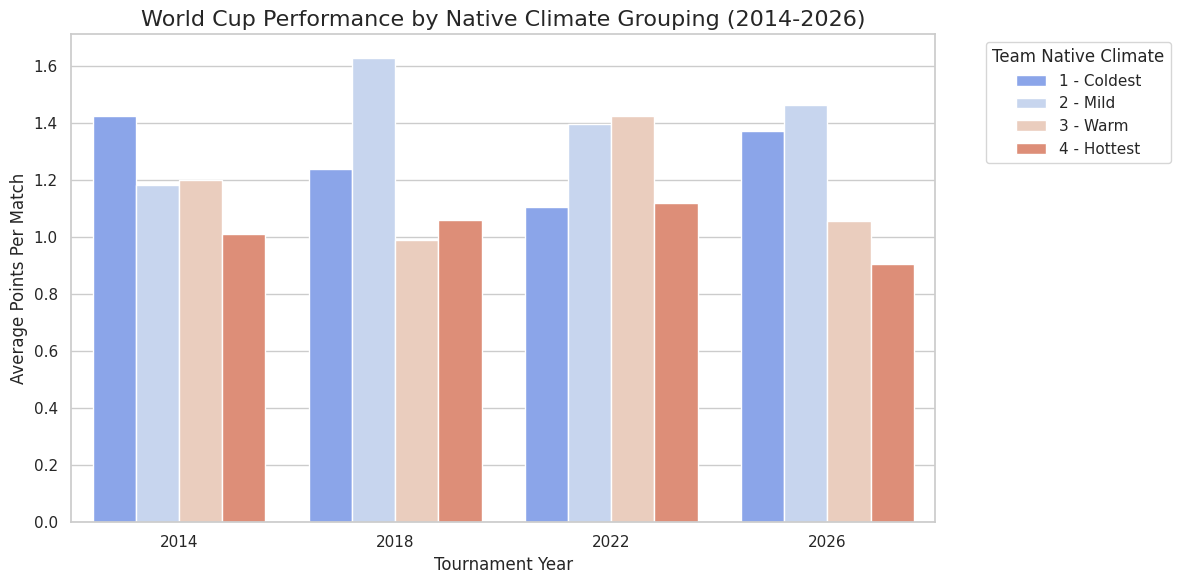

In [9]:
import matplotlib.pyplot as plt
import seaborn as sb
import numpy as np

df_merged["pts_per_match"] = df_merged["Pts"] / df_merged["Pld"]

#AI used to figure out a way to use math to divide countries into 4 buckets of temperatures, "pd.qcut"
df_merged["native_climate_bucket"] = pd.qcut(
    df_merged["avg_temp_c"],
    q=4,
    labels=[
        "1 - Coldest",
        "2 - Mild",
        "3 - Warm",
        "4 - Hottest"
    ]
)
df_analysis_1 = df_merged.copy()

print("--- How it Divided the Climates ---")
# observed=True because of warning
climate_summary = df_analysis_1.groupby("native_climate_bucket", observed=True)["avg_temp_c"].agg(["min", "max", "count"])
print(climate_summary)
print("\n" + "-"*50 + "\n")

#Used AI to help me figure out how to format tables
plt.figure(figsize=(12, 6))
sb.set_theme(style="whitegrid")

ax = sb.barplot(
    data=df_analysis_1,
    x="Tournament_Year",
    y="pts_per_match",
    hue="native_climate_bucket",
    palette="coolwarm",
    errorbar=None
)

plt.title("World Cup Performance by Native Climate Grouping (2014-2026)", fontsize=16)
plt.xlabel("Tournament Year", fontsize=12)
plt.ylabel("Average Points Per Match", fontsize=12)
plt.legend(title="Team Native Climate", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show



In [10]:
display(df_merged.head(20))

,Pos,Grp,country,Pld,W,D,L,GF,GA,GD,Pts,Final result,Tournament_Year,climate_join_key,continent,avg_temp_c,pts_per_match,native_climate_bucket
0,1.0,G,Germany,7.0,6.0,1.0,0.0,18.0,4.0,+14,19.0,Champions,2014,Germany,Europe,9.58,2.714286,1 - Coldest
1,2.0,F,Argentina,7.0,5.0,1.0,1.0,8.0,4.0,+4,16.0,Runners-up,2014,Argentina,South America,16.30,2.285714,3 - Warm
2,3.0,B,Netherlands,7.0,5.0,2.0,0.0,15.0,4.0,+11,17.0,Third place,2014,Netherlands,Europe,10.49,2.428571,1 - Coldest
3,4.0,A,Brazil,7.0,3.0,2.0,2.0,11.0,14.0,−3,11.0,Fourth place,2014,Brazil,South America,25.44,1.571429,4 - Hottest
4,5.0,C,Colombia,5.0,4.0,0.0,1.0,12.0,4.0,+8,12.0,Eliminated in quarter-finals,2014,Colombia,South America,25.00,2.400000,4 - Hottest
5,6.0,H,Belgium,5.0,4.0,0.0,1.0,6.0,3.0,+3,12.0,Eliminated in quarter-finals,2014,Belgium,Europe,10.67,2.400000,2 - Mild
6,7.0,E,France,5.0,3.0,1.0,1.0,10.0,3.0,+7,10.0,Eliminated in quarter-finals,2014,France,Europe,11.66,2.000000,2 - Mild
7,8.0,D,Costa Rica,5.0,2.0,3.0,0.0,5.0,2.0,+3,9.0,Eliminated in quarter-finals,2014,Costa Rica,Central America,24.83,1.800000,4 - Hottest
8,9.0,B,Chile,4.0,2.0,1.0,1.0,6.0,4.0,+2,7.0,Eliminated in round of 16,2014,Chile,South America,9.39,1.750000,1 - Coldest
9,10.0,A,Mexico,4.0,2.0,1.0,1.0,5.0,3.0,+2,7.0,Eliminated in round of 16,2014,Mexico,North America,21.31,1.750000,3 - Warm


--- What is the Correlation ---
Correlation between Climate Shock and Goal Difference Per Match: 0.207
--------------------------------------------------



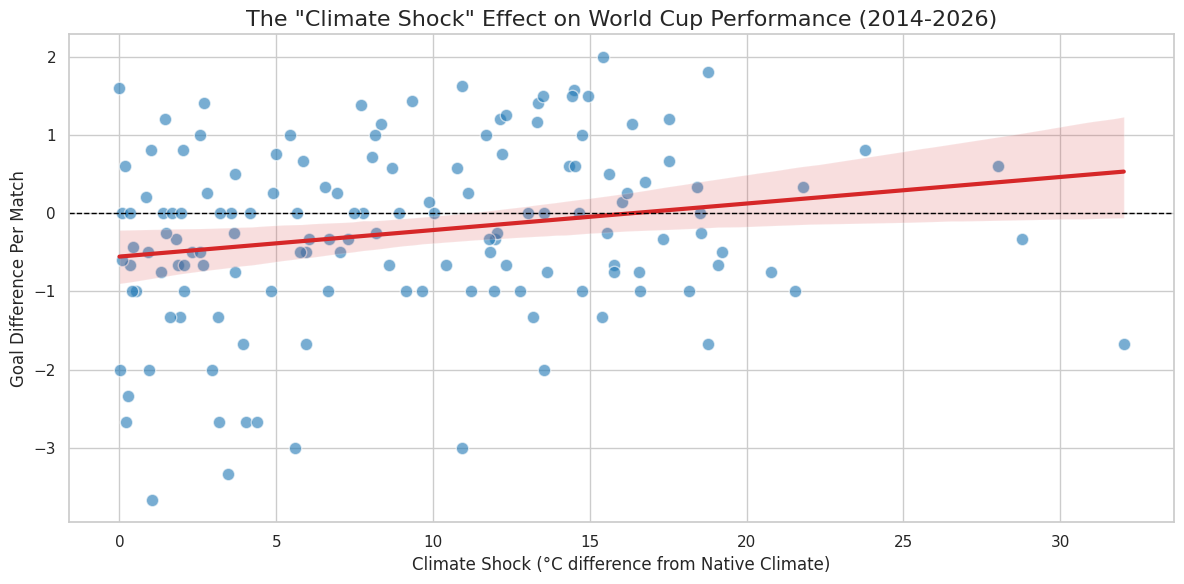

In [11]:
# Found temps of the tournaments on https://climatecup.org/
host_temps = {
    2014: 25.0,
    2018: 20.0,
    2022: 28.0,
    2026: 24.0
}

df_merged["host_temp_c"] = df_merged["Tournament_Year"].map(host_temps)
df_merged["climate_shock"] = abs(df_merged["avg_temp_c"] - df_merged["host_temp_c"])
df_merged["gd_per_match"] = (df_merged["GF"] - df_merged["GA"]) / df_merged["Pld"]
df_analysis_2 = df_merged.copy()

plt.figure(figsize=(12, 6))
sb.set_theme(style="whitegrid")

ax = sb.regplot(
    data=df_analysis_2,
    x="climate_shock",
    y="gd_per_match",
    scatter_kws={"alpha": 0.6, "color": "#1f77b4", "edgecolor": "w", "s": 80},
    line_kws={"color": "#d62728", "linewidth": 3}
)

plt.title('The "Climate Shock" Effect on World Cup Performance (2014-2026)', fontsize=16)
plt.xlabel("Climate Shock (°C difference from Native Climate)", fontsize=12)
plt.ylabel("Goal Difference Per Match", fontsize=12)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

correlation = df_analysis_2["climate_shock"].corr(df_analysis_2["gd_per_match"])
print("--- What is the Correlation ---")
print(f"Correlation between Climate Shock and Goal Difference Per Match: {correlation:.3f}")
print("-"*50 + "\n")

plt.tight_layout()
plt.show()

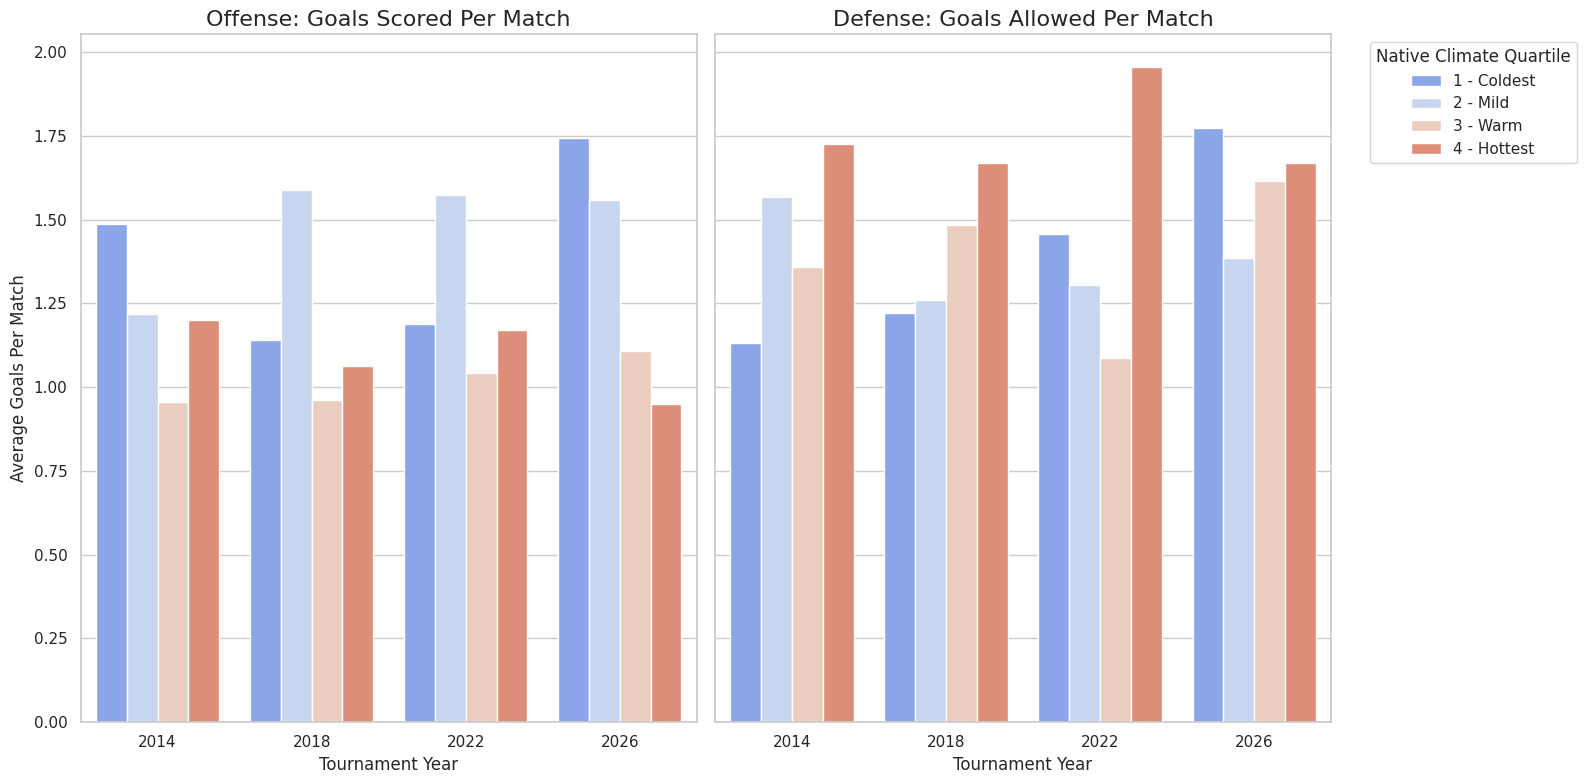

In [12]:
df_merged["gf_per_match"] = df_merged["GF"] / df_merged["Pld"]
df_merged["ga_per_match"] = df_merged["GA"] / df_merged["Pld"]
df_analysis_3 = df_merged.copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=True)
sb.set_theme(style="whitegrid")

sb.barplot(
    data=df_analysis_3,
    x="Tournament_Year",
    y="gf_per_match",
    hue="native_climate_bucket",
    palette="coolwarm",
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title("Offense: Goals Scored Per Match", fontsize=16)
axes[0].set_xlabel("Tournament Year", fontsize=12)
axes[0].set_ylabel("Average Goals Per Match", fontsize=12)
axes[0].legend().remove()

sb.barplot(
    data=df_analysis_3,
    x="Tournament_Year",
    y="ga_per_match",
    hue="native_climate_bucket",
    palette="coolwarm",
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title('Defense: Goals Allowed Per Match', fontsize=16)
axes[1].set_xlabel("Tournament Year", fontsize=12)
axes[1].set_ylabel("")
axes[1].legend(title="Native Climate Quartile", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

In [13]:
outliers = df_analysis_2[
    (df_analysis_2["climate_shock"] >= 10.0) &
    (df_analysis_2["pts_per_match"] >= 2.0)
].copy()

outliers = outliers.sort_values(by="climate_shock", ascending=False)


print("--- The Outliers: High Climate Shock, High Performance (2.0+ Pts/Match) ---")
display(outliers[["country", "Tournament_Year", "avg_temp_c", "host_temp_c", "climate_shock", "pts_per_match"]])

--- The Outliers: High Climate Shock, High Performance (2.0+ Pts/Match) ---


,country,Tournament_Year,avg_temp_c,host_temp_c,climate_shock,pts_per_match
100,Norway,2026,2.21,24.0,21.79,2.000000
69,England,2022,9.24,28.0,18.76,2.000000
68,Netherlands,2022,10.49,28.0,17.51,2.200000
65,France,2022,11.66,28.0,16.34,2.285714
0,Germany,2014,9.58,25.0,15.42,2.714286
98,England,2026,9.24,24.0,14.76,2.375000
2,Netherlands,2014,10.49,25.0,14.51,2.428571
5,Belgium,2014,10.67,25.0,14.33,2.400000
112,Netherlands,2026,10.49,24.0,13.51,2.000000
6,France,2014,11.66,25.0,13.34,2.000000


# **FINAL REPORT**

  **Data Motivation:** The main research question of this project is whether a sudden, large change in playing climate (a "Climate Shock") negatively impacts a national soccer team's performance at the FIFA World Cup. I chose this topic because national sports federations spend millions on heat acclimatization camps ahead of summer tournaments. Finding a correlation between native climate alignment and tournament success would help sports scientists justify these massive infrastructure costs, while also giving sports analysts and oddsmakers a new metric for predicting match outcomes. I also got into thinking about this from following the 2026 World Cup and seeing many headlines talking about high temperatures and the controversial inclusion of ads during water breaks.

  Once the raw data was acquired and merged, my question had to change. My initial hypothesis assumed that extreme heat would reduce the overall Points Per Match for cold weather nations. However, early visualizations revealed a massive confounding variable: the world's most talented and well funded football programs(like France, Germany, and England) primarily come from cold or mild native climates, and their elite talent easily overpowered the climate disadvantage. As a result, my research question shifted from simply asking if warmer countries do better in hotter tournaments, to asking how it mechanically affects players on the pitch, leading me to split the analysis into offensive vs defensive.


  **Sources, Provenance & Terms:** The primary data for this project consists of two sources published by the Wikimedia Foundation under the Creative Commons CC BY-SA 4.0 open data license. The 1st source covers the average yearly temperature by country, which I collected via a single-page scrape using Python's requests and pandas' read_html method. The 2nd source covers the final tournament standings(points, goals for, goals against) for the 2014, 2018, 2022, and 2026 FIFA World Cups. I accessed this data by making a Tier-2 multi-page scrape that looped through the four respective Wikipedia URLs, with a 2 sec rate limit and using validation to get the correct tables. Both scripts passed an honest User-Agent identifying the requests as student coursework.
  
  To accurately calculate the "Climate Shock" metric during the analysis, a third source was used: tournament temperatures from climatecup.org. This source aggregates historical meteorological records and stadium infrastructure data(such as evaluating Qatar 2022 at a 28°C average despite stadium AC). Because I only needed 4 data points(one for each tournament year), it was manually collected, verified, and hardcoded into a Python dictionary rather than scraped.


  **Data Dictionary & Metadata:** Table above has been fully updated


  **Data Cleaning Steps Narrative:** The path from raw to final data required handling several HTML issues. For the Wikipedia climate data, I dropped arbitrary index columns and renamed variables for consistency. The main challenge here was isolating the Celsius float from a messy string. To achieve this, I stripped hidden HTML non-breaking spaces(\xa0), split the string to discard the Fahrenheit conversion, and replaced Unicode minus signs(−) with standard ASCII hyphens(-) so the text could be a float64 data type for analysis.
  
  For the World Cup standings, cleaning involved dropping empty visual divider rows(loaded as NaNs) and using regular expressions to strip host nation markers added to host countries. The most important data cleaning decision happened during the integration prep. Because FIFA recognizes England, Wales, and Scotland as independent nations, but the climate data groups them under the "United Kingdom," merging directly on the team name originally caused a uniqueness failure. To fix this, I made a dedicated climate_join_key column to map these names. This decision preserved the football team names for my analysis through a many-to-one merge with the climate table.

  The largest flaw I found was while trying to make the verification suite. Since I scraped the 2014 (32 teams), 2018 (32 teams), 2022 (32 teams), and 2026 (48 teams) World Cups, I expected exactly 144 rows before my merge. However, my initial cleaned output resulted in exactly 112 rows. By investigating the data, I realized the entire 2022 tournament was missing.
  
  When I looked at the raw scraped data for 2022, I found a weirdly formatted table with column headers named 0, 1, 2, 3 instead of Team or Pts. After looking at the actual 2022 Wikipedia page, I discovered that the editors had placed a "Draw Result" layout table near the top of the article. Because this layout table contained the text string "Pos" and was more than 32 rows, my read_html loop grabbed it, thought it was the Final Standings table, and moved on to the next year. Because this fake table didn't have a Team column, my dropna(subset=['Team']) command later deleted the entire 2022 tournament from my dataset.
  
  I learned that relying on just the length of a table and a single keyword (match="Pos") is not a strict enough selector when dealing with web data. I fixed this by updating my scraping loop to require strict structural validation: it only accepts a table if it has +32 rows and explicitly contains both the "Team" and "Pts" columns in its header. This immediately bypassed the other table, scraped the actual 2022 standings, and made my row count back to 144.


  **Integration & Verification:** The two datasets were integrated using a pandas left merge, with the World Cup standings as the base left table and the climate data as the right. To resolve geopolitical naming problems without dropping rows or overwriting the original team names, the merge made climate_join_key  to map against the climate table's country column. This merge was strictly enforced with the many-to-one parameter, which acts as a built in protection to instantly catch any unexpected Cartesian fan outs that would occur if the climate reference table contained accidental duplicates.
  
  To verify the final dataset's accuracy, I made a custom verification suite containing 4 assertions. The suite checked that the final row count remained exactly 144(no fan-out), zero missing temperatures, numeric value ranges were valid(no negative points), and that uniqueness was preserved. This suite successfully caught a major logical error: it failed loudly on the Uniqueness check, alerting me that because both England and Wales qualified for the 2022 tournament, mapping them both to "United Kingdom" created duplicate entries for that year. Catching this through the verification suite is what made me make the dedicated climate-join-key mentioned earlier, which resolved the duplication while keeping the data verifiable. Finally, to prove the suite's robustness, I purposefully passed a broken dataframe containing a duplicated row into it, demonstrating that the code catches flaws and fails loudly.


  **Findings:** The most significant finding of this project directly contradicted my initial hypothesis: "Climate Shock" does not inherently destroy a team's overall performance, evidenced by a positive correlation(0.207) with Goal Difference. Instead, the analysis revealed that by splitting performance into offensive and defensive metrics, the data showed that extreme heat does not degrade offence of cold-weather teams, but it does drastically increase their goals conceded(heavily in 2026). This suggests that offensive ability, which relies on controlling ball possession and making the opponent run, persists in the heat. In contrast, defensive stamina, which requires exhausting off-the-ball pressure, measurably degrades in the heat. Furthermore, in the hottest overall tournament(2022 at 28°C), average points leveled out remarkably across all four climate quartiles, implying that extreme heat may finally act as an equalizer. But, when isolating the ultimate outliers who endured a 10°C+ climate shock but still averaged High-level points(2.0+), the data showed almost exclusively European nations, with the sole exception of Argentina.
  
  To be honest about uncertainty, I must cleanly separate what the data mathematically proves from what I suspect is true. The data proves that cold weather nations overcome massive climate shocks, but I strongly suspect this is driven by a confounding variable: national football wealth, which creates a selection bias in the data. The only nations geographically capable of experiencing a massive 20°C+ shock in a hot tournament are northern, highly developed countries that have the funds to climate train and recruit te best players. I suspect that top-tier federations utilize expensive acclimatization camps, advanced sports science, and possession based tactics to override environmental disadvantages, but this dataset lacks the financial metrics to definitively prove that. Additionally, applying a single average temperature to an entire tournament creates inherent uncertainty. Local weather variations(like 2026 being in 3 extremly different countries), varying kickoff times, and unrecorded technological mitigations(like artificial stadium cooling) mean teams experienced micro-climates not perfectly captured by the synthesized host_temp_c variable.


  **What is Missing:** This dataset excludes several important populations and geographical realities, which limits the scope of the conclusions. First, the data excludes the Women's FIFA World Cup, meaning these conclusions about physiological heat fatigue only apply to elite male athletes and cannot be generalized across all genders. Second, the dataset excludes all national teams that failed to qualify for the final tournaments. By only analyzing the top 32 to 48 teams in the world, the data suffers from survivorship bias; we are only looking at teams already elite enough to reach the finals. The consequence of this exclusion is that we cannot see if "Climate Shock" disproportionately destroys lower-funded, developing nations during the hard, multi-year continental qualification rounds.
  
  Geographically, the data excludes regional micro-climates by assigning a single average temperature to entire countries. For example, averaging the arctic cold of Alaska with the tropical heat of Florida gives the US a single, misleadingly mild temperature, which misrepresents the actual biological acclimatization of a player born and raised in Miami. Because of this, one major question this data cannot answer is: Does a national team's native climate actually matter in modern football? Because the vast majority of elite players, regardless of whether they play for hot-weather nations like Senegal or Brazil, or cold-weather nations like Norway, actually live, train, and play their professional club football in temperate European leagues for ten months of the year. This dataset cannot answer whether its measuring true national climate acclimatization, or simply the standardized conditioning of European club football.


  **AI Use Log & Reflection:** AI was used whenever I came across a problem I was spending too much time on or when I had no idea where to begin. The first instance of AI was during the setup in P1, where an update forced me to include StringIO when grabbing tables from the Climate source. The second instance of AI was during the cleaning phase where I wasnt able to find the difference between Unicode minus sign and ASCII minus sign, as I cleaned up the Climate data. The most AI I used was for trying to make a way for me to correctly implement FBref data into my project. I kept getting returned a 403 Forbidden HTTP status. I used AI to try a variety of solutions all of which failed, so I ended up looking for another source which I eventually discovered, Wikipedia. While joining the 2 datasets, I had to use AI to help develop and create the climate-join-key. During the analysis I used AI to figure out a way to divide the countries into 4 even buckets. I also used AI to help me figure out how to format visuals for my tables. The only AI tool I used was Google Gemini.

  The most surprising thing I discovered was that I had to be extremely specific to the AI for it to give me what I was looking for. I also discovered AI was good for basic task like formatting tables but worse at problem solving. My biggest reflection with AI was its failure to make the FBred data work even though I tried working with the AI on that issue for nearly an hour straight. This kind of taught me that if the AI doesnt know how to solve it, its better to go through a different path.  


  **Reproducibility:** https://github.com/SidhPatel-27/dsa405-project

  To reproduce this analysis, a user can clone the repo linked above and open the Notebook. The code requires a standard Python data science environment with the pandas, requests, matplotlib, seaborn, and all other imported libraries installed. A user simply needs to select "Restart Kernel and Run All Cells." The code will automatically detect the prescraped wiki_climate.csv and world_cup_standings.csv files if stored in the repository's data/raw/ directory and load them directly into the memory. This guarantees that a stranger will get the exact same mathematical results and visual charts without risking a timeout error or being blocked by Wikipedia's rate limits.
  
  If a user wishes to audit the original web sources, they can go to the SOURCES.md file included in the repository, which contains the direct URLs to the Wikipedia climate table and the four historical World Cup tournament pages. To execute a fresh scrape, the user only needs to delete the two CSV files from their local data/raw/ folder before running the notebook. The acquisition code will automatically detect the missing files, pause for the hardcoded 2-second rate limits, and re-download the data using an honest User-Agent header.